# Genomic Prediction and Candidate Marker Discovery in Rice

**Dataset:** RiceVarMap v2.0, 529 rice accessions, 5000 LD-pruned SNP markers, 10 agronomic traits

**Two objectives, kept separate throughout**

1. Prediction: how accurately each trait can be estimated from genome-wide markers
2. Discovery: which genomic positions carry that information

These have different success criteria. A model can predict well while the markers it relies on
shift between runs, and a marker set can be informative without improving prediction.

### What changed from the earlier version of this analysis

| Issue | Effect |
|---|---|
| `-9` missing-value sentinel not detected | Grain thickness R2 went from -0.086 to roughly 0.46 once handled |
| Marker selection done on the full panel before CV | Inflates R2; measured per trait in Section 5 |
| Early stopping evaluated on the validation fold | Now uses an inner split of the training data only |
| GBLUP allele frequencies from train+val | Now estimated from the training fold only |
| Ridge alpha fixed at 100 | Now chosen by inner cross-validation on the training fold |
| Subpopulation label counted as a marker in the importance ranking | Ranking is over markers only |
| Selection reported as a single top-200 list | Replaced by resampling frequency (stability selection) |
| Association test corrected on subpopulation labels only | Replaced with genotype-PC correction |
| Correlated markers counted as separate findings | Collapsed into loci by LD clumping |
| Comparison with known loci used an unverified coordinate | Replaced by a permutation test against a published position table |

Every performance number comes from nested cross-validation. Nothing computed on the full panel is
reported as an accuracy figure. The discovery pass in Sections 6 to 8 does use the full panel, which is
normal for producing a marker list, and is never used to produce an R2.

Importance is now measured by total split gain rather than split count. This changes numbers slightly
compared with earlier runs, so every table must be regenerated by running the notebook again.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import os
import re
import sys
import time
import random
import numpy as np
import pandas as pd
import lightgbm as lgb
import sklearn
import scipy
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from collections import Counter
from statsmodels.stats.multitest import multipletests
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import r2_score, mean_squared_error, accuracy_score, f1_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.decomposition import PCA

random.seed(42)
np.random.seed(42)

SEED        = 42
TOP_K       = 200      # markers retained per selection pass
N_SPLITS    = 5        # outer CV folds
N_BOOT      = 50       # resamples for stability selection
BOOT_FRAC   = 0.80     # sample fraction per resample
STAB_THRESH = 0.60     # marker must survive this share of resamples
N_STRUCT_PC = 10       # genotype PCs used as structure covariates
CLUMP_KB    = 250      # window for collapsing markers into one locus
N_EST       = 1500     # boosting rounds before early stopping
IMP_TYPE    = 'gain'   # importance = total split gain
ALPHAS      = np.logspace(0, 4, 9)   # Ridge alpha grid, searched inside each training fold

OUT = '/kaggle/working' if os.path.isdir('/kaggle/working') else '.'

kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

print("python    ", sys.version.split()[0])
print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)
print("scipy     ", scipy.__version__)
print("sklearn   ", sklearn.__version__)
print("lightgbm  ", lgb.__version__)
print("output dir", OUT)

python     3.12.13
numpy      2.0.2
pandas     2.3.3
scipy      1.16.3
sklearn    1.6.1
lightgbm   4.6.0
output dir /kaggle/working


## 2. Data Loading

Two files are merged on accession ID: the SNP matrix with phenotypes, and cultivar metadata
carrying subpopulation labels. Genotypes use additive 0/1/2 encoding, the count of alternate alleles.
Paths below are for Kaggle; change them if running elsewhere.

In [2]:
df = pd.read_csv("/kaggle/input/datasets/roma06yadav/filt-ricevarmap/reduced_df_529x5010.csv")
dfm = pd.read_csv("/kaggle/input/datasets/roma06yadav/matched-data/matched_data.csv")
dfm.rename(columns={'Cultivar ID': 'id_name'}, inplace=True)

def_mer = pd.merge(df, dfm, on='id_name', how='left')

traits = ['Plant_height', 'Heading_date', 'Num_panicles',
          'Num_effective_panicles', 'Yield', 'Grain_weight',
          'Spikelet_length', 'Grain_length', 'Grain_width', 'Grain_thickness']

snp_cols = [c for c in def_mer.columns if c.startswith('vg')]
def_mer = def_mer[snp_cols + traits + ['Subpopulation']]

le = LabelEncoder()
def_mer['subpop_encoded'] = le.fit_transform(def_mer['Subpopulation'].fillna('Unknown'))
def_mer.drop(columns=['Subpopulation'], inplace=True)

print("merged shape:", def_mer.shape)
print("markers:", len(snp_cols), " traits:", len(traits))
print("subpopulations:", list(le.classes_))

merged shape: (529, 5011)
markers: 5000  traits: 10
subpopulations: ['Aus', 'Indica I', 'Indica II', 'Indica III', 'Indica Intermediate', 'Intermediate', 'Japonica Intermediate', 'Temperate Japonica', 'Tropical Japonica', 'VI/Aromatic']


### 2.1 The `-9` sentinel

RiceVarMap encodes missing phenotypes as `-9`, following PLINK convention. Code that tests only for
`NaN` does not catch this, and affected rows enter the model as genuine measurements. An accession
with a recorded grain length of -9 mm is an extreme outlier in a variable whose true range is about
6 to 11 mm.

Between one and eight rows per trait are affected. The consequence is far larger than that count
suggests: grain thickness R2 went from -0.086 to roughly 0.46 once the rows were removed.

In [3]:
for t in traits:
    def_mer[t] = def_mer[t].replace(-9, np.nan)

print(f"{'Trait':<25} {'n':>5} {'dropped':>8}   range")
for t in traits:
    y = def_mer[t].values.astype(np.float32)
    n_miss = int(np.isnan(y).sum())
    print(f"{t:<25} {len(y)-n_miss:>5} {n_miss:>8}   {np.nanmin(y):.2f} to {np.nanmax(y):.2f}")

Trait                         n  dropped   range
Plant_height                528        1   68.40 to 206.73
Heading_date                529        0   45.00 to 149.00
Num_panicles                522        7   3.00 to 47.20
Num_effective_panicles      522        7   3.00 to 45.80
Yield                       522        7   4.41 to 92.66
Grain_weight                521        8   14.01 to 41.48
Spikelet_length             522        7   13.68 to 33.34
Grain_length                525        4   6.13 to 10.97
Grain_width                 525        4   1.96 to 4.38
Grain_thickness             525        4   1.58 to 2.45


In [4]:
# marker columns first, subpopulation label as the last column
X_full = np.nan_to_num(def_mer[snp_cols + ['subpop_encoded']].values.astype(np.float32), nan=0.0)
X_snp_only = np.nan_to_num(def_mer[snp_cols].values.astype(np.float32), nan=0.0)
N_M = len(snp_cols)

print("X_full:", X_full.shape, " X_snp_only:", X_snp_only.shape)
print()
print("Residual genotype missingness is imputed as 0 (homozygous reference). This is a")
print("conservative default, not a neutral one: it assigns the majority genotype and will")
print("slightly attenuate effects at markers with appreciable missingness. Markers above 5%")
print("missing were removed earlier.")

X_full: (529, 5001)  X_snp_only: (529, 5000)

Residual genotype missingness is imputed as 0 (homozygous reference). This is a
conservative default, not a neutral one: it assigns the majority genotype and will
slightly attenuate effects at markers with appreciable missingness. Markers above 5%
missing were removed earlier.


## 3. Helper Functions

In [5]:
def lgb_reg(seed=SEED, colsample=0.4):
    return lgb.LGBMRegressor(
        n_estimators=N_EST, learning_rate=0.02, num_leaves=15,
        min_child_samples=15, subsample=0.7, subsample_freq=1,
        colsample_bytree=colsample, reg_alpha=0.5, reg_lambda=1.0,
        importance_type=IMP_TYPE, random_state=seed, verbose=-1)


def lgb_clf(seed=SEED, colsample=0.5):
    return lgb.LGBMClassifier(
        n_estimators=N_EST, learning_rate=0.02, num_leaves=15,
        min_child_samples=15, subsample=0.7, subsample_freq=1,
        colsample_bytree=colsample, reg_alpha=0.5, reg_lambda=1.0,
        importance_type=IMP_TYPE, random_state=seed, verbose=-1)


def fit_es(model, Xtr, ytr, i_tr, i_es):
    """Fit with early stopping on an inner split of the training data."""
    model.fit(Xtr[i_tr], ytr[i_tr], eval_set=[(Xtr[i_es], ytr[i_es])],
              callbacks=[lgb.early_stopping(80, verbose=False)])
    return model


def compute_G_split(X_train, X_val):
    """Genomic relationship matrix with allele frequencies estimated from the
    training fold only. Using train+val frequencies leaks validation genotypes
    into the centring step."""
    p = np.clip(X_train.mean(axis=0) / 2, 1e-6, 1 - 1e-6)
    denom = 2 * np.sum(p * (1 - p))
    Zt, Zv = X_train - 2 * p, X_val - 2 * p
    return (Zt @ Zt.T) / denom, (Zv @ Zt.T) / denom


def gblup_predict(G_train, y_train, G_cross, lam=1.0):
    n = len(y_train)
    mu = y_train.mean()
    alpha = np.linalg.solve(G_train + lam * np.eye(n), y_train - mu)
    return mu + G_cross @ alpha


def trait_arrays(trait):
    """y, X with subpop column last, markers only, subpop; rows with missing y dropped."""
    y_all = def_mer[trait].values.astype(np.float64)
    m = ~np.isnan(y_all)
    return y_all[m], X_full[m], X_snp_only[m], def_mer['subpop_encoded'].values[m]


def struct_covariates(X_train, n_pc=N_STRUCT_PC):
    """Genotype PCs of the given rows, used to correct for population structure."""
    sc = StandardScaler().fit(X_train)
    pca = PCA(n_components=n_pc, random_state=SEED).fit(sc.transform(X_train))
    return pca.transform(sc.transform(X_train))


def association_test(X_snp, y, covariates):
    """Per-marker correlation after regressing covariates out of both sides.
    Returns raw p-values, FDR rejection flags and partial correlations."""
    n = len(y)
    D = np.column_stack([np.ones(n), covariates.astype(np.float64)])
    Q, _ = np.linalg.qr(D)
    resid = lambda M: M - Q @ (Q.T @ M)

    y_r = resid(y.reshape(-1, 1).astype(np.float64)).ravel()
    X_r = resid(X_snp.astype(np.float64))

    Xc = X_r - X_r.mean(axis=0)
    yc = y_r - y_r.mean()
    den = np.sqrt((Xc ** 2).sum(axis=0) * (yc ** 2).sum())
    den[den == 0] = np.nan
    r = (Xc.T @ yc) / den

    dof = n - D.shape[1] - 1
    tstat = r * np.sqrt(dof / np.clip(1 - r ** 2, 1e-12, None))
    p = np.nan_to_num(2 * stats.t.sf(np.abs(tstat), dof), nan=1.0)
    reject, _, _, _ = multipletests(p, alpha=0.05, method='fdr_bh')
    return p, reject, np.nan_to_num(r)


def parse_position(snp_id):
    """vg0141830776_A -> (chromosome 1, position 41830776)"""
    m = re.match(r'vg(\d{2})(\d+)', snp_id)
    return (int(m.group(1)), int(m.group(2))) if m else (None, None)


def clump(scores, window_kb=CLUMP_KB, ascending=True):
    """Greedy clumping. Take the best-scoring marker, drop everything within the
    window on the same chromosome, repeat."""
    ranked = scores.sort_values(ascending=ascending)
    window = window_kb * 1000
    leads, tagged, claimed = [], {}, []

    for snp, sc in ranked.items():
        c, pos = parse_position(snp)
        if c is None:
            continue
        hit = next((i for i, (lc, lp) in enumerate(claimed)
                    if lc == c and abs(lp - pos) <= window), None)
        if hit is None:
            claimed.append((c, pos))
            leads.append({'lead_snp': snp, 'chr': c, 'pos': pos, 'score': sc})
            tagged[snp] = [snp]
        else:
            tagged[leads[hit]['lead_snp']].append(snp)

    out = pd.DataFrame(leads)
    if not out.empty:
        out['n_tagged'] = out['lead_snp'].map(lambda s: len(tagged[s]))
    return out, tagged


snp_idx = {s: i for i, s in enumerate(snp_cols)}
marker_pos = pd.DataFrame([parse_position(s) for s in snp_cols], columns=['chr', 'pos'])
print("helpers defined")

helpers defined


## 4. Nested Cross-Validation

Within each of five outer folds, everything downstream of the raw data is recomputed from that fold's
training partition alone: the importance ranking, the association test, the PCA, the Ridge alpha
search and the inner early-stopping split. The validation fold is used only for evaluation.

| Model | Input | Why it is here |
|---|---|---|
| GBLUP | Relationship matrix over all markers | Field-standard baseline, unsupervised, no selection step |
| LightGBM, all markers | 5000 markers plus subpopulation | Boosting without feature selection |
| LightGBM, top-200 | Fold-local top-200 markers plus subpopulation | Prediction from a discovered marker set |
| Ridge, top-200 | Same markers, alpha chosen by inner CV | Isolates model class from marker selection |
| LightGBM on PCA of top-200 | 10 PCs fitted on training rows, plus subpopulation | Dimensionality reduction as a prediction input |
| Ridge and LightGBM on loci only | Fold-local loci: top-200 by importance and top-200 by association, clumped | Prediction from the small locus set itself |
| LightGBM classifier | Top-200 markers, Low / Medium / High tertiles from training cutoffs | Categorical version of the trait |

The importance ranking covers markers only. The subpopulation label is appended to the model input
afterwards, so it is never ranked as if it were a marker.

The loci-only models use a single-model importance ranking, not full stability selection, because
repeating 50 resamples inside every fold of every trait would take many hours.

In [6]:
def nested_cv(trait, verbose=True):
    y, Xf, Xs, subpop = trait_arrays(trait)
    n = len(y)
    keys = ['gblup', 'all_snp', 'top200', 'ridge200', 'pca200', 'loci_ridge',
            'loci_lgb', 'loci_n', 'clf_acc', 'clf_f1', 'rmse200', 'ridge_alpha']
    res = {k: [] for k in keys}

    for fi, (tr, va) in enumerate(kf.split(Xf)):
        y_tr, y_va = y[tr], y[va]
        Xf_tr, Xf_va = Xf[tr], Xf[va]
        Xs_tr, Xs_va = Xs[tr], Xs[va]
        i_tr, i_es = train_test_split(np.arange(len(tr)), test_size=0.15,
                                      random_state=SEED + fi)

        # all-marker model, also gives the importance ranking over markers only
        sel = fit_es(lgb_reg(colsample=0.2), Xf_tr, y_tr, i_tr, i_es)
        res['all_snp'].append(r2_score(y_va, sel.predict(Xf_va)))
        imp = sel.feature_importances_[:N_M]
        top_idx = np.argsort(imp)[::-1][:TOP_K]
        cols = np.r_[top_idx, N_M]

        # top-200 markers plus subpopulation, boosting
        mdl = fit_es(lgb_reg(colsample=0.5), Xf_tr[:, cols], y_tr, i_tr, i_es)
        pred = mdl.predict(Xf_va[:, cols])
        res['top200'].append(r2_score(y_va, pred))
        res['rmse200'].append(mean_squared_error(y_va, pred) ** 0.5)

        # same markers, Ridge with alpha chosen inside the training fold
        sc = StandardScaler().fit(Xs_tr[:, top_idx])
        rg = RidgeCV(alphas=ALPHAS).fit(sc.transform(Xs_tr[:, top_idx]), y_tr)
        res['ridge200'].append(r2_score(y_va, rg.predict(sc.transform(Xs_va[:, top_idx]))))
        res['ridge_alpha'].append(rg.alpha_)

        # PCA of the top-200 markers, fitted on training rows only
        pca = PCA(n_components=N_STRUCT_PC, random_state=SEED).fit(sc.transform(Xs_tr[:, top_idx]))
        P_tr = np.column_stack([pca.transform(sc.transform(Xs_tr[:, top_idx])), Xf_tr[:, -1]])
        P_va = np.column_stack([pca.transform(sc.transform(Xs_va[:, top_idx])), Xf_va[:, -1]])
        mp = fit_es(lgb_reg(colsample=0.8), P_tr, y_tr, i_tr, i_es)
        res['pca200'].append(r2_score(y_va, mp.predict(P_va)))

        # categorical version: tertile cutoffs from training rows only
        q1, q2 = np.quantile(y_tr, [1 / 3, 2 / 3])
        c_tr = np.where(y_tr <= q1, 0, np.where(y_tr <= q2, 1, 2))
        c_va = np.where(y_va <= q1, 0, np.where(y_va <= q2, 1, 2))
        clf = fit_es(lgb_clf(), Xf_tr[:, cols], c_tr, i_tr, i_es)
        pc = clf.predict(Xf_va[:, cols])
        res['clf_acc'].append(accuracy_score(c_va, pc))
        res['clf_f1'].append(f1_score(c_va, pc, average='macro'))

        # loci only: importance top-200 AND association top-200 (fold-local), clumped
        p_tr, _, _ = association_test(Xs_tr, y_tr, struct_covariates(Xs_tr))
        cand = sorted(set(top_idx) & set(np.argsort(p_tr)[:TOP_K]))
        lead_idx = []
        if cand:
            leads, _ = clump(pd.Series(p_tr[cand], index=[snp_cols[i] for i in cand]))
            lead_idx = [snp_idx[s] for s in leads['lead_snp']]
        res['loci_n'].append(len(lead_idx))
        if len(lead_idx) >= 2:
            sl = StandardScaler().fit(Xs_tr[:, lead_idx])
            rl = RidgeCV(alphas=ALPHAS).fit(sl.transform(Xs_tr[:, lead_idx]), y_tr)
            res['loci_ridge'].append(r2_score(y_va, rl.predict(sl.transform(Xs_va[:, lead_idx]))))
            lc = np.r_[lead_idx, N_M]
            ml = fit_es(lgb_reg(colsample=0.8), Xf_tr[:, lc], y_tr, i_tr, i_es)
            res['loci_lgb'].append(r2_score(y_va, ml.predict(Xf_va[:, lc])))
        else:
            res['loci_ridge'].append(np.nan)
            res['loci_lgb'].append(np.nan)

        # GBLUP, training-only allele frequencies
        Gt, Gc = compute_G_split(Xs_tr, Xs_va)
        res['gblup'].append(r2_score(y_va, gblup_predict(Gt, y_tr, Gc)))

    out = {k: (np.nanmean(v), np.nanstd(v)) for k, v in res.items()}
    out['n'] = n
    out['folds'] = res
    if verbose:
        print(f"{trait:<25} n={n:<4} GBLUP={out['gblup'][0]:.3f} all={out['all_snp'][0]:.3f} "
              f"top200={out['top200'][0]:.3f} ridge={out['ridge200'][0]:.3f} "
              f"pca={out['pca200'][0]:.3f} loci_ridge={out['loci_ridge'][0]:.3f} "
              f"acc={out['clf_acc'][0]:.3f}")
    return out


t0 = time.time()
cv_results = {}
for t in traits:
    cv_results[t] = nested_cv(t)
print("elapsed seconds:", round(time.time() - t0))

Plant_height              n=528  GBLUP=0.657 all=0.689 top200=0.672 ridge=0.691 pca=0.657 loci_ridge=0.618 acc=0.661
Heading_date              n=529  GBLUP=0.464 all=0.502 top200=0.452 ridge=0.377 pca=0.397 loci_ridge=0.283 acc=0.648
Num_panicles              n=522  GBLUP=0.349 all=0.354 top200=0.329 ridge=0.308 pca=0.254 loci_ridge=0.249 acc=0.508
Num_effective_panicles    n=522  GBLUP=0.357 all=0.375 top200=0.354 ridge=0.344 pca=0.294 loci_ridge=0.240 acc=0.531
Yield                     n=522  GBLUP=0.218 all=0.221 top200=0.183 ridge=0.124 pca=0.108 loci_ridge=0.043 acc=0.540
Grain_weight              n=521  GBLUP=0.238 all=0.187 top200=0.127 ridge=0.096 pca=0.077 loci_ridge=0.051 acc=0.459
Spikelet_length           n=522  GBLUP=0.299 all=0.347 top200=0.347 ridge=0.329 pca=0.290 loci_ridge=0.264 acc=0.531
Grain_length              n=525  GBLUP=0.457 all=0.474 top200=0.452 ridge=0.413 pca=0.392 loci_ridge=0.413 acc=0.604
Grain_width               n=525  GBLUP=0.625 all=0.653 top200=0.

In [7]:
rows = []
for t in traits:
    r = cv_results[t]
    rows.append({
        'Trait': t, 'N': r['n'],
        'GBLUP': r['gblup'][0],
        'AllSNP': r['all_snp'][0],
        'Top200_LGB': r['top200'][0],
        'Top200_Ridge': r['ridge200'][0],
        'Top200_PCA': r['pca200'][0],
        'Loci_Ridge': r['loci_ridge'][0],
        'Loci_LGB': r['loci_lgb'][0],
        'Loci_n': r['loci_n'][0],
        'Clf_Acc': r['clf_acc'][0],
        'Clf_F1': r['clf_f1'][0],
        'SD_Top200': r['top200'][1],
        'RMSE_Top200': r['rmse200'][0],
    })

cv_table = pd.DataFrame(rows).set_index('Trait').round(3)
pd.set_option('display.width', 200)
print(cv_table.to_string())
print()
print(cv_table[['GBLUP', 'AllSNP', 'Top200_LGB', 'Top200_Ridge', 'Top200_PCA',
                'Loci_Ridge', 'Loci_LGB']].mean().round(3).to_string())
print()
print("random-guess accuracy for three classes: 0.333")

                          N  GBLUP  AllSNP  Top200_LGB  Top200_Ridge  Top200_PCA  Loci_Ridge  Loci_LGB  Loci_n  Clf_Acc  Clf_F1  SD_Top200  RMSE_Top200
Trait                                                                                                                                                  
Plant_height            528  0.657   0.689       0.672         0.691       0.657       0.618     0.642    32.4    0.661   0.642      0.033       18.154
Heading_date            529  0.464   0.502       0.452         0.377       0.397       0.283     0.350    32.8    0.648   0.644      0.050       11.248
Num_panicles            522  0.349   0.354       0.329         0.308       0.254       0.249     0.296    32.8    0.508   0.496      0.040        4.617
Num_effective_panicles  522  0.357   0.375       0.354         0.344       0.294       0.240     0.285    31.8    0.531   0.523      0.037        4.457
Yield                   522  0.218   0.221       0.183         0.124       0.108       0

### 4.1 Reading this table

The sentences below are generated from the table above, so they follow whatever this run produced.

In [8]:
t = cv_table
n = len(t)
print(f"all markers >= top-200 LGB on {int((t['AllSNP'] >= t['Top200_LGB']).sum())}/{n} traits")
print(f"top-200 LGB   >  top-200 Ridge on {int((t['Top200_LGB'] > t['Top200_Ridge']).sum())}/{n} traits")
print(f"top-200 LGB   >  top-200 PCA   on {int((t['Top200_LGB'] > t['Top200_PCA']).sum())}/{n} traits")
print(f"top-200 LGB   >  GBLUP         on {int((t['Top200_LGB'] > t['GBLUP']).sum())}/{n} traits")
print(f"all markers   >  GBLUP         on {int((t['AllSNP'] > t['GBLUP']).sum())}/{n} traits")
print(f"GBLUP is best of the four main models on: "
      f"{list(t[['GBLUP','AllSNP','Top200_LGB','Top200_Ridge']].idxmax(axis=1).pipe(lambda s: s[s=='GBLUP']).index)}")
print()
print("mean R2 gap, top-200 LGB minus all markers:",
      round((t['Top200_LGB'] - t['AllSNP']).mean(), 3))
print("mean R2 gap, top-200 LGB minus GBLUP:      ",
      round((t['Top200_LGB'] - t['GBLUP']).mean(), 3))
print("mean R2 gap, loci-only Ridge minus top-200 Ridge:",
      round((t['Loci_Ridge'] - t['Top200_Ridge']).mean(), 3))
print()
print("Gaps smaller than the fold-to-fold SD (SD_Top200 column) should not be read as differences.")

all markers >= top-200 LGB on 10/10 traits
top-200 LGB   >  top-200 Ridge on 9/10 traits
top-200 LGB   >  top-200 PCA   on 10/10 traits
top-200 LGB   >  GBLUP         on 3/10 traits
all markers   >  GBLUP         on 8/10 traits
GBLUP is best of the four main models on: ['Grain_weight', 'Grain_thickness']

mean R2 gap, top-200 LGB minus all markers: -0.027
mean R2 gap, top-200 LGB minus GBLUP:       -0.014
mean R2 gap, loci-only Ridge minus top-200 Ridge: -0.06

Gaps smaller than the fold-to-fold SD (SD_Top200 column) should not be read as differences.


## 5. Quantifying the Leakage

The earlier pipeline selected the top 200 markers using importances computed on the full panel, then
trained and evaluated every fold on that fixed list. Each validation sample had already influenced
which markers were selected before being used to test them.

This cell runs that procedure with the same folds and the same model settings as the nested run,
so the difference between the two is attributable to selection alone.

In [9]:
def naive_selection_folds(trait):
    """Deliberately leaky: rank markers on the full panel, then cross-validate on
    that fixed list. This is the procedure being measured, not recommended."""
    y, Xf, Xs, _ = trait_arrays(trait)
    full = lgb_reg(colsample=0.2).fit(Xf, y)
    top_idx = np.argsort(full.feature_importances_[:N_M])[::-1][:TOP_K]
    cols = np.r_[top_idx, N_M]

    fold_r2 = []
    for fi, (tr, va) in enumerate(kf.split(Xf)):
        i_tr, i_es = train_test_split(np.arange(len(tr)), test_size=0.15,
                                      random_state=SEED + fi)
        mdl = fit_es(lgb_reg(colsample=0.5), Xf[tr][:, cols], y[tr], i_tr, i_es)
        fold_r2.append(r2_score(y[va], mdl.predict(Xf[va][:, cols])))
    return np.array(fold_r2)


leak_rows = []
print(f"{'Trait':<25} {'Naive':>7} {'Nested':>7} {'Inflation':>10} {'SD':>6} {'folds>0':>8}")
for t in traits:
    naive = naive_selection_folds(t)
    nested = np.array(cv_results[t]['folds']['top200'])
    diff = naive - nested
    leak_rows.append({'Trait': t, 'Naive': naive.mean(), 'Nested': nested.mean(),
                      'Inflation': diff.mean(), 'SD': diff.std(),
                      'Folds_positive': int((diff > 0).sum())})
    print(f"{t:<25} {naive.mean():>7.3f} {nested.mean():>7.3f} {diff.mean():>+10.3f} "
          f"{diff.std():>6.3f} {int((diff > 0).sum()):>5}/{N_SPLITS}")

leak_table = pd.DataFrame(leak_rows).set_index('Trait')
print()
print(f"mean inflation: {leak_table['Inflation'].mean():+.3f}   "
      f"range: {leak_table['Inflation'].min():+.3f} to {leak_table['Inflation'].max():+.3f}")

Trait                       Naive  Nested  Inflation     SD  folds>0
Plant_height                0.733   0.672     +0.061  0.019     5/5
Heading_date                0.569   0.452     +0.117  0.036     5/5
Num_panicles                0.501   0.329     +0.171  0.023     5/5
Num_effective_panicles      0.519   0.354     +0.165  0.038     5/5
Yield                       0.378   0.183     +0.195  0.040     5/5
Grain_weight                0.310   0.127     +0.183  0.055     5/5
Spikelet_length             0.511   0.347     +0.164  0.025     5/5
Grain_length                0.576   0.452     +0.124  0.023     5/5
Grain_width                 0.730   0.629     +0.101  0.027     5/5
Grain_thickness             0.562   0.430     +0.132  0.022     5/5

mean inflation: +0.141   range: +0.061 to +0.195


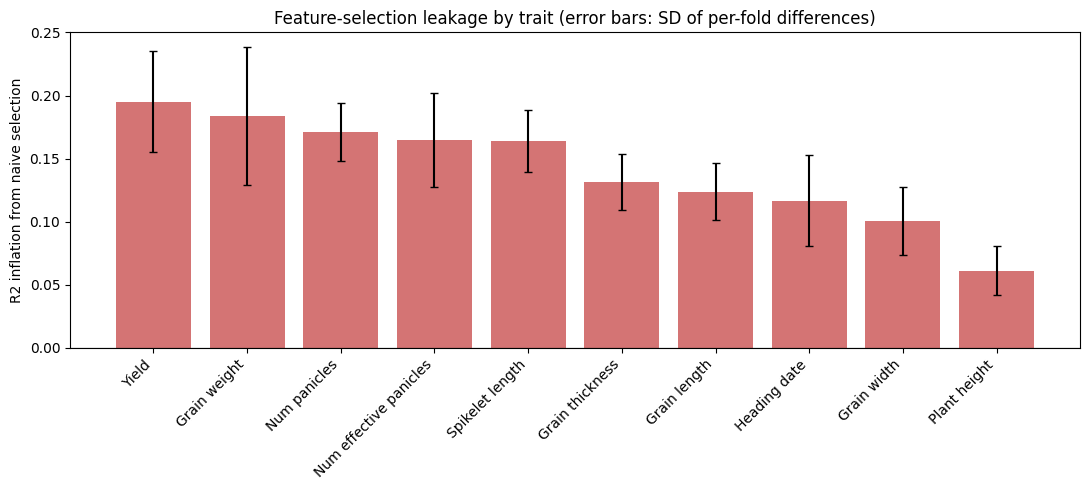

correlation between nested R2 and inflation across 10 traits: -0.949
With ten traits this is descriptive only. A negative value means inflation was larger
where genuine signal was weaker, which is what overfitting of the selection step predicts.


In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
lt = leak_table.sort_values('Inflation', ascending=False)
ax.bar(range(len(lt)), lt['Inflation'], yerr=lt['SD'], color='indianred', alpha=0.85, capsize=3)
ax.set_xticks(range(len(lt)))
ax.set_xticklabels([t.replace('_', ' ') for t in lt.index], rotation=45, ha='right')
ax.set_ylabel('R2 inflation from naive selection')
ax.set_title('Feature-selection leakage by trait (error bars: SD of per-fold differences)')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout(); plt.show()

corr = np.corrcoef(leak_table['Nested'], leak_table['Inflation'])[0, 1]
print(f"correlation between nested R2 and inflation across 10 traits: {corr:+.3f}")
print("With ten traits this is descriptive only. A negative value means inflation was larger")
print("where genuine signal was weaker, which is what overfitting of the selection step predicts.")

## 6. Stability Selection

A marker appearing once in a top-200 list may have been lucky. Markers within one LD block carry
near-identical information, so a model can pick a different one on each run while accuracy stays the
same. Resampling makes this measurable: the data is subsampled 50 times, importance is recomputed on
each subsample, and the share of runs in which a marker lands in the top 200 becomes its confidence
measure.

This is a discovery pass on the full panel. It produces a marker list, not an accuracy figure.

In [11]:
def stability_selection(trait, n_boot=N_BOOT, frac=BOOT_FRAC, top_k=TOP_K):
    y, Xf, _, _ = trait_arrays(trait)
    rng = np.random.RandomState(SEED)
    counts = np.zeros(N_M)

    for b in range(n_boot):
        idx = rng.choice(len(y), size=int(frac * len(y)), replace=False)
        mdl = lgb_reg(seed=b, colsample=0.2).fit(Xf[idx], y[idx])
        top = np.argsort(mdl.feature_importances_[:N_M])[::-1][:top_k]
        counts[top] += 1

    return pd.Series(counts / n_boot, index=snp_cols).sort_values(ascending=False)


t0 = time.time()
stability = {}
print(f"{'Trait':<25} {'>=80%':>7} {'>=60%':>7} {'>=50%':>7}")
for t in traits:
    s = stability_selection(t)
    stability[t] = s
    print(f"{t:<25} {int((s>=0.8).sum()):>7} {int((s>=0.6).sum()):>7} {int((s>=0.5).sum()):>7}")
print("elapsed seconds:", round(time.time() - t0))

Trait                       >=80%   >=60%   >=50%
Plant_height                   42      81     107
Heading_date                   43      92     125
Num_panicles                   22      63      95
Num_effective_panicles         25      66      99
Yield                          18      48      75
Grain_weight                   37      90     130
Spikelet_length                41      82     113
Grain_length                   36      83     113
Grain_width                    48      88     109
Grain_thickness                42      90     116
elapsed seconds: 5546


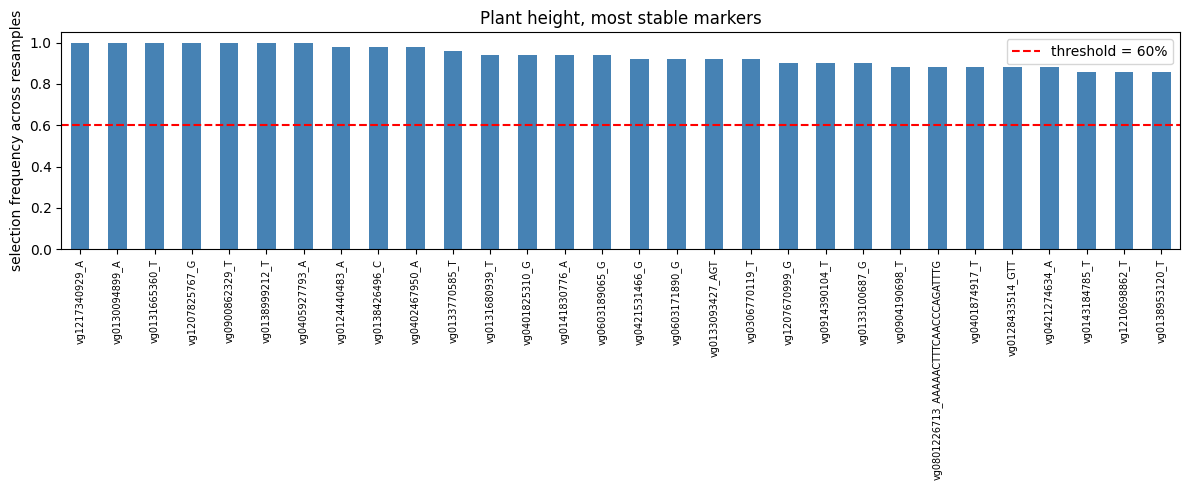

In [12]:
s = stability['Plant_height']
fig, ax = plt.subplots(figsize=(12, 5))
s.head(30).plot(kind='bar', color='steelblue', ax=ax)
ax.axhline(STAB_THRESH, color='red', linestyle='--', label=f'threshold = {STAB_THRESH:.0%}')
ax.set_ylabel('selection frequency across resamples')
ax.set_title('Plant height, most stable markers')
ax.tick_params(axis='x', rotation=90, labelsize=7)
ax.legend()
plt.tight_layout(); plt.show()

## 7. Association Testing with Genotype-PC Correction

Importance from a boosted model says how much a marker reduced prediction error inside that model.
Whether the marker is statistically associated with the trait is a separate question and needs a
separate test.

Both the marker columns and the trait are residualised against structure covariates, and the
correlation is computed on what remains. Without correction, many markers look associated only
because they tag ancestry.

Genotype PCs are used rather than subpopulation labels. Labels remove only between-group mean
differences, while ancestry in rice is continuous and relatedness exists within each labelled group.
The cell below runs both so the difference is visible.

This test has no kinship term, so structure is only partly controlled. A mixed model with a
relationship matrix would be stricter. The counts below are FDR-significant markers at 5%.

In [13]:
print(f"{'Trait':<25} {'dummy corr':>12} {'PC corr':>10}")

assoc_p = {}
assoc_r = {}
for t in traits:
    y, _, Xs, subpop = trait_arrays(t)
    pcs = struct_covariates(Xs)
    dummies = pd.get_dummies(subpop, drop_first=True).values.astype(np.float64)

    _, rej_d, _ = association_test(Xs, y, dummies)
    p_pc, rej_p, r_pc = association_test(Xs, y, pcs)

    assoc_p[t] = pd.Series(p_pc, index=snp_cols).sort_values()
    assoc_r[t] = pd.Series(r_pc, index=snp_cols)
    print(f"{t:<25} {int(rej_d.sum()):>12} {int(rej_p.sum()):>10}")

print()
print("A count in the thousands does not mean thousands of loci. Rice self-pollinates and LD")
print("extends 100 to 500 kb, so one real signal pulls many correlated markers over the line.")
print("Section 8 collapses these into independent loci.")

Trait                       dummy corr    PC corr
Plant_height                      4850        478
Heading_date                      2316        293
Num_panicles                       181        120
Num_effective_panicles             213        112
Yield                               74          8
Grain_weight                         2          8
Spikelet_length                   1812         86
Grain_length                       185         79
Grain_width                        622        118
Grain_thickness                    160         29

A count in the thousands does not mean thousands of loci. Rice self-pollinates and LD
extends 100 to 500 kb, so one real signal pulls many correlated markers over the line.
Section 8 collapses these into independent loci.


## 8. From Markers to Loci

Rice is a selfing species and linkage disequilibrium extends 100 to 500 kb. With 5000 markers over
roughly 373 Mb, spacing averages about 75 kb, well inside one LD block. Forty markers clustered on
one chromosome arm are one locus tagged forty times, not forty findings.

A candidate is a marker that is stable in at least 60% of resamples and also in the top 200 by
association. Candidates are then clumped: the strongest marker is kept, everything within 250 kb on
the same chromosome is absorbed, and the process repeats.

In [14]:
print(f"{'Trait':<25} {'stable':>8} {'candidates':>12} {'loci':>7}")

candidates, loci_tables = {}, {}
for t in traits:
    stable = set(stability[t][stability[t] >= STAB_THRESH].index)
    assoc_top = set(assoc_p[t].head(TOP_K).index)
    cand = sorted(stable & assoc_top)
    candidates[t] = cand

    if cand:
        loci, _ = clump(assoc_p[t][cand])
        loci['r'] = [assoc_r[t][s] for s in loci['lead_snp']]
        loci.insert(0, 'trait', t)
    else:
        loci = pd.DataFrame()
    loci_tables[t] = loci
    print(f"{t:<25} {len(stable):>8} {len(cand):>12} {len(loci):>7}")

loci_all = pd.concat([v for v in loci_tables.values() if not v.empty], ignore_index=True)
loci_all = loci_all.rename(columns={'score': 'p_value', 'r': 'partial_r'})
print()
print("total loci across traits:", len(loci_all))

Trait                       stable   candidates    loci
Plant_height                    81           35      24
Heading_date                    92           41      31
Num_panicles                    63           35      24
Num_effective_panicles          66           37      25
Yield                           48           19      17
Grain_weight                    90           40      27
Spikelet_length                 82           41      28
Grain_length                    83           45      27
Grain_width                     88           31      21
Grain_thickness                 90           34      23

total loci across traits: 247


In [15]:
for t in traits:
    lt = loci_tables[t]
    print(f"\n{t}: {len(lt)} loci")
    if lt.empty:
        continue
    show = lt[['lead_snp', 'chr', 'pos', 'score', 'r', 'n_tagged']].copy()
    show['pos'] = show['pos'].map(lambda x: f"{x:,}")
    show['score'] = show['score'].map(lambda x: f"{x:.1e}")
    show['r'] = show['r'].map(lambda x: f"{x:+.2f}")
    show.columns = ['lead_marker', 'chr', 'position', 'p_value', 'partial_r', 'n_tagged']
    print(show.to_string(index=False))


Plant_height: 24 loci
    lead_marker  chr   position p_value partial_r  n_tagged
 vg0904190698_T    9  4,190,698 1.1e-20     +0.39         5
 vg0124440483_A    1 24,440,483 3.3e-13     +0.31         1
 vg0130755959_A    1 30,755,959 1.4e-12     -0.30         1
 vg0401258410_C    4  1,258,410 6.8e-11     +0.28         1
 vg0401825310_G    4  1,825,310 9.2e-11     +0.28         2
 vg1210521054_T   12 10,521,054 3.9e-10     +0.27         2
 vg1207670999_G   12  7,670,999 7.9e-10     +0.27         1
 vg0431676320_A    4 31,676,320 1.2e-08     -0.25         1
 vg0704380123_A    7  4,380,123 5.4e-08     +0.24         1
 vg1217340929_A   12 17,340,929 1.2e-07     +0.23         1
 vg0405927793_A    4  5,927,793 1.6e-07     +0.23         1
 vg0402467950_A    4  2,467,950 2.4e-07     +0.22         2
 vg0421274634_A    4 21,274,634 4.5e-07     -0.22         2
 vg0617829293_A    6 17,829,293 1.6e-05     +0.19         2
 vg0809208374_A    8  9,208,374 1.8e-05     -0.19         1
 vg1218096374_T  

### 8.1 Comparison with published loci

Published GWAS exists on this panel (the RiceVarMap GWAS pages, and later work such as Zhou et al.
2026), so these loci are not new findings. The useful question is whether the pipeline, which was
never shown the published positions, lands near them more often than random markers would.

The table below holds the plant-height lead positions on chromosome 1 from the RiceVarMap GWAS page
(indica accessions). Check them against the page and confirm the reference build matches the marker
coordinates before using the result. Positions for the other chromosomes (the page lists leads on
chromosomes 2, 3, 4, 6, 7 and 10) must be added by hand. The test only covers chromosomes present in
this table.

With eleven published sites on one chromosome and a 250 kb window, a large share of chromosome 1 is
covered, so some agreement is expected by chance. The permutation test below measures that.

In [16]:
pub_ph = pd.DataFrame({'chr': 1, 'pos': [23720143, 31754198, 33271810, 33440209, 35617816,
                                          35647613, 37838382, 38424728, 38428840, 38608956,
                                          39946773]})
# add rows for chromosomes 2, 3, 4, 6, 7, 10 from the RiceVarMap plant height GWAS page, e.g.
# pub_ph.loc[len(pub_ph)] = {'chr': 2, 'pos': 12345678}


def n_near(chrs, poss, pub, window):
    hits = 0
    for c, p in zip(chrs, poss):
        pp = pub.loc[pub['chr'] == c, 'pos'].values
        if len(pp) and np.abs(pp - p).min() <= window:
            hits += 1
    return hits


def overlap_test(loci, pub, window_kb=CLUMP_KB, n_perm=2000, seed=SEED):
    window = window_kb * 1000
    chrs = sorted(set(pub['chr']) & set(loci['chr']))
    ours = loci[loci['chr'].isin(chrs)]
    if ours.empty:
        return None
    obs = n_near(ours['chr'].values, ours['pos'].values, pub, window)
    pool = marker_pos[marker_pos['chr'].isin(chrs)].reset_index(drop=True)
    rng = np.random.RandomState(seed)
    null = np.zeros(n_perm)
    for b in range(n_perm):
        pick = pool.iloc[rng.choice(len(pool), size=len(ours), replace=False)]
        null[b] = n_near(pick['chr'].values, pick['pos'].values, pub, window)
    return {'chromosomes': chrs, 'our_loci': len(ours), 'observed_near': obs,
            'null_mean': null.mean(), 'p_perm': (1 + (null >= obs).sum()) / (n_perm + 1)}


lt = loci_tables['Plant_height']
if not lt.empty:
    out = overlap_test(lt, pub_ph)
    if out is None:
        print("no plant height loci on the chromosomes in the published table")
    else:
        print("chromosomes compared:", out['chromosomes'])
        print("our loci on those chromosomes:", out['our_loci'])
        print(f"within {CLUMP_KB} kb of a published lead: {out['observed_near']}")
        print(f"expected for random markers: {out['null_mean']:.1f}")
        print(f"permutation p-value: {out['p_perm']:.3f}")

    c1 = lt[lt['chr'] == 1]
    print("\nnearest published chr1 lead for each of our chr1 loci:")
    for _, row in c1.iterrows():
        d = np.abs(pub_ph.loc[pub_ph['chr'] == 1, 'pos'].values - row['pos']).min() / 1e6
        print(f"  {row['lead_snp']:<22} {row['pos']:>12,}   {d:.2f} Mb")

chromosomes compared: [1]
our loci on those chromosomes: 3
within 250 kb of a published lead: 1
expected for random markers: 0.6
permutation p-value: 0.469

nearest published chr1 lead for each of our chr1 loci:
  vg0124440483_A           24,440,483   0.72 Mb
  vg0130755959_A           30,755,959   1.00 Mb
  vg0133100687_G           33,100,687   0.17 Mb


### 8.2 Is chromosome clustering real or a density effect?

If loci pile up on one chromosome, that could mean something, or it could mean that chromosome simply
holds more markers or sits in a region of strong ancestry structure. The test compares each
chromosome's share of loci with its share of the 5000 markers. Counts are small, so treat the
p-values as a rough screen, and note that structure-driven clustering would not be caught by it.

In [17]:
chr_share = marker_pos['chr'].value_counts(normalize=True).sort_index()
n_chr = len(chr_share)

print(f"{'Trait':<25} chromosomes with more loci than marker density predicts")
for t in traits:
    lt = loci_tables[t]
    if lt.empty:
        continue
    k = lt['chr'].value_counts()
    n_l = len(lt)
    flags = []
    for c, cnt in k.items():
        p = stats.binom.sf(cnt - 1, n_l, chr_share.loc[c]) * n_chr
        if min(p, 1.0) < 0.05:
            flags.append(f"chr{c} ({cnt} of {n_l}, p={min(p,1.0):.3f})")
    print(f"{t:<25} {', '.join(flags) if flags else 'none'}")

print()
print("p-values are one-sided binomial with Bonferroni correction over chromosomes.")
all_k = loci_all['chr'].value_counts()
print("all traits pooled (loci can repeat across traits, so pooled counts are not independent):")
print(all_k.sort_index().to_string())

Trait                     chromosomes with more loci than marker density predicts
Plant_height              chr4 (6 of 24, p=0.027)
Heading_date              none
Num_panicles              none
Num_effective_panicles    none
Yield                     none
Grain_weight              none
Spikelet_length           chr4 (7 of 28, p=0.012)
Grain_length              chr3 (7 of 27, p=0.050)
Grain_width               none
Grain_thickness           chr5 (4 of 23, p=0.013)

p-values are one-sided binomial with Bonferroni correction over chromosomes.
all traits pooled (loci can repeat across traits, so pooled counts are not independent):
chr
1     51
2     16
3     17
4     29
5     12
6     29
7     14
8     19
9     19
10     5
11    14
12    22


### 8.3 Split-half replication

The accessions are split at random into two halves and the association test is run on each. Two
unrelated halves share little noise, so markers that rank highly in both are less likely to be
chance. Each half has about 260 accessions, so power is lower than on the full panel and failure to
replicate a single locus is weak evidence either way.

In [18]:
def split_half(trait, seed=SEED):
    y, _, Xs, _ = trait_arrays(trait)
    perm = np.random.RandomState(seed).permutation(len(y))
    halves = [perm[:len(y) // 2], perm[len(y) // 2:]]
    ps = []
    for ix in halves:
        p, _, _ = association_test(Xs[ix], y[ix], struct_covariates(Xs[ix]))
        ps.append(p)
    top = [set(np.argsort(p)[:TOP_K]) for p in ps]
    rho = stats.spearmanr(-np.log10(ps[0] + 1e-300), -np.log10(ps[1] + 1e-300))[0]
    lt = loci_tables[trait]
    rep = 0
    if not lt.empty:
        li = [snp_idx[s] for s in lt['lead_snp']]
        rep = int(sum((ps[0][i] < 0.05) and (ps[1][i] < 0.05) for i in li))
    return len(top[0] & top[1]), rho, rep, len(lt)


expected = TOP_K ** 2 / N_M
print(f"{'Trait':<25} {'top-200 overlap':>16} {'rank corr':>10} {'loci p<0.05 in both':>21}")
for t in traits:
    ov, rho, rep, nl = split_half(t)
    print(f"{t:<25} {ov:>16} {rho:>10.2f} {rep:>12} of {nl}")
print(f"\noverlap expected by chance: {expected:.0f}")

Trait                      top-200 overlap  rank corr   loci p<0.05 in both
Plant_height                            37       0.11           23 of 24
Heading_date                            33       0.07           19 of 31
Num_panicles                            14       0.07           13 of 24
Num_effective_panicles                  17       0.09           14 of 25
Yield                                    7       0.02            3 of 17
Grain_weight                            14       0.12           10 of 27
Spikelet_length                         28       0.05           18 of 28
Grain_length                            10       0.04            9 of 27
Grain_width                             20       0.10           12 of 21
Grain_thickness                         19       0.09           12 of 23

overlap expected by chance: 8


## 9. Summary

In [19]:
final = cv_table[['N', 'GBLUP', 'AllSNP', 'Top200_LGB', 'Top200_Ridge', 'Loci_Ridge', 'Clf_Acc']].copy()
final['Candidates'] = [len(candidates[t]) for t in final.index]
final['Loci'] = [len(loci_tables[t]) for t in final.index]
final['Leakage'] = leak_table['Inflation'].round(3)
print(final.to_string())

                          N  GBLUP  AllSNP  Top200_LGB  Top200_Ridge  Loci_Ridge  Clf_Acc  Candidates  Loci  Leakage
Trait                                                                                                               
Plant_height            528  0.657   0.689       0.672         0.691       0.618    0.661          35    24    0.061
Heading_date            529  0.464   0.502       0.452         0.377       0.283    0.648          41    31    0.117
Num_panicles            522  0.349   0.354       0.329         0.308       0.249    0.508          35    24    0.171
Num_effective_panicles  522  0.357   0.375       0.354         0.344       0.240    0.531          37    25    0.165
Yield                   522  0.218   0.221       0.183         0.124       0.043    0.540          19    17    0.195
Grain_weight            521  0.238   0.187       0.127         0.096       0.051    0.459          40    27    0.183
Spikelet_length         522  0.299   0.347       0.347         0

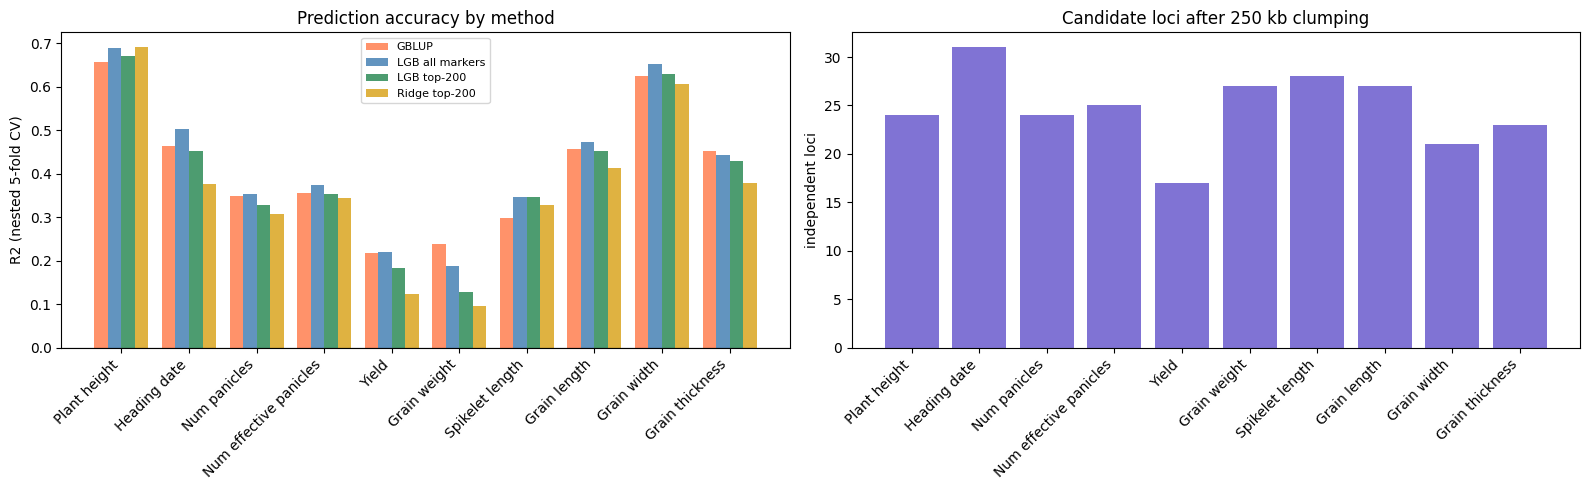

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
labels = [t.replace('_', ' ') for t in traits]
x = np.arange(len(traits))
w = 0.2

for i, (col, colour, name) in enumerate([
        ('GBLUP', 'coral', 'GBLUP'),
        ('AllSNP', 'steelblue', 'LGB all markers'),
        ('Top200_LGB', 'seagreen', 'LGB top-200'),
        ('Top200_Ridge', 'goldenrod', 'Ridge top-200')]):
    axes[0].bar(x + (i - 1.5) * w, cv_table[col], w, label=name, color=colour, alpha=0.85)

axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=45, ha='right')
axes[0].set_ylabel('R2 (nested 5-fold CV)')
axes[0].set_title('Prediction accuracy by method')
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].legend(fontsize=8)

axes[1].bar(x, [len(loci_tables[t]) for t in traits], color='slateblue', alpha=0.85)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=45, ha='right')
axes[1].set_ylabel('independent loci')
axes[1].set_title(f'Candidate loci after {CLUMP_KB} kb clumping')

plt.tight_layout(); plt.show()

## 10. Saving Results

In [21]:
loci_all.to_csv(f"{OUT}/loci_all_traits.csv", index=False)

cand_rows = []
for t in traits:
    for s in candidates[t]:
        c, pos = parse_position(s)
        cand_rows.append({'trait': t, 'marker': s, 'chr': c, 'pos': pos,
                          'stability': stability[t][s], 'p_value': assoc_p[t][s],
                          'partial_r': assoc_r[t][s]})
pd.DataFrame(cand_rows).to_csv(f"{OUT}/candidates_all_traits.csv", index=False)

cv_table.to_csv(f"{OUT}/cv_results.csv")
leak_table.to_csv(f"{OUT}/leakage.csv")
pd.DataFrame(stability).to_pickle(f"{OUT}/stability.pkl")

print("saved to", OUT)
for f in ['loci_all_traits.csv', 'candidates_all_traits.csv', 'cv_results.csv',
          'leakage.csv', 'stability.pkl']:
    print(" ", f, os.path.getsize(f"{OUT}/{f}"), "bytes")

saved to /kaggle/working
  loci_all_traits.csv 20907 bytes
  candidates_all_traits.csv 31276 bytes
  cv_results.csv 1001 bytes
  leakage.csv 992 bytes
  stability.pkl 487152 bytes


## 11. What This Analysis Supports

**Prediction.** Read the tables in Sections 4 and 9 for the numbers. The design supports comparing
methods only where gaps exceed the fold-to-fold SD. Marker selection, PCA reduction and a loci-only
model are all compared against using every marker, so a claim that any of them helps must be backed by
that comparison, not assumed.

**Leakage.** Section 5 measures how much R2 is inflated when markers are chosen on the full panel
before cross-validation, with folds and model settings held identical. This is a measurement on one
panel of 529 accessions with one model family. It shows the size of the effect here, not a general
constant.

**Candidate loci.** The loci are markers that survive resampling, are independently flagged by a
structure-corrected association test, and are collapsed into approximately independent regions. This
is evidence of statistical association and nothing more. Published GWAS already exists on this
panel, so the list is not a discovery. It is a set of candidates produced by a leakage-controlled
pipeline, offered unverified, together with the overlap and replication checks in Sections 8.1 to 8.3.

**Not shown.** No images, mutations or biological validation are involved anywhere in this work. The
pipeline has been run on rice only, and nothing here shows it transfers to another species.

**Limitations.**
- 529 accessions against 5000 markers is a small-n, wide-p setting.
- Phenotypes come from one environment, so environmental variance is not modelled.
- Structure correction uses genotype PCs, not a mixed model with a kinship term.
- The loci-only models use single-model importance, not full stability selection.
- Stability and association are computed on the full panel, so they describe the panel, not
  out-of-sample performance.
- The 5000 markers are LD-pruned, which limits mapping resolution.
- A held-out validation of the loci in an independent panel has not been done.

**References**

- Meuwissen, Hayes and Goddard (2001). Prediction of total genetic value using genome-wide dense marker maps. Genetics 157, 1819-1829.
- VanRaden (2008). Efficient methods to compute genomic predictions. Journal of Dairy Science 91, 4414-4423.
- Meinshausen and Buhlmann (2010). Stability selection. Journal of the Royal Statistical Society B 72, 417-473.
- Benjamini and Hochberg (1995). Controlling the false discovery rate. Journal of the Royal Statistical Society B 57, 289-300.
- Zhao et al. (2021). An inferred functional impact map of genetic variants in rice. Molecular Plant 14, 1584-1599. (RiceVarMap v2.0)
- Spindel et al. (2015). Genomic selection and association mapping in rice. PLOS Genetics. doi:10.1371/journal.pgen.1004982
- Grenier et al. (2015). PLOS ONE. doi:10.1371/journal.pone.0136594
- Zhou et al. (2026). Integrating predictive models and GWAS to identify candidate loci and genes for agronomic traits in rice. Frontiers in Plant Science.

Verify every reference against the source before submission.